# Homework 2: MDP & DP & MC
**Reinforcement Learning (CSCI-SHU 375), Fall 2026** — Yixia Yu (yy5091@nyu.edu)

This notebook contains the code for Exercises 1, 2, 4, 5 and 6. The written answers and the pseudo-code (Exercises 1.3 and 3) are in the PDF.

In [1]:
import os
import time

import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.stats import poisson

os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

## Exercise 1: Gridworld

States are numbered $1,\dots,16$ row by row, with state 1 in the top-left corner (Figure 1 of the assignment). States 1 and 10 are terminal, every transition gives reward $-1$, and there is no discounting.

In [2]:
ACTIONS = ["up", "down", "right", "left"]
ARROWS = ["↑", "↓", "→", "←"]
TERMINAL = {1, 10}
NON_TERMINAL = [s for s in range(1, 17) if s not in TERMINAL]

def next_state(s, a):
    r, c = divmod(s - 1, 4)
    if a == "up":
        r = max(r - 1, 0)
    elif a == "down":
        r = min(r + 1, 3)
    elif a == "right":
        c = min(c + 1, 3)
    else:
        c = max(c - 1, 0)
    return 4 * r + c + 1

# NEXT[s, i] = state reached from s with action ACTIONS[i] (row 0 is unused)
NEXT = np.zeros((17, 4), dtype=int)
for s in range(1, 17):
    for i, a in enumerate(ACTIONS):
        NEXT[s, i] = next_state(s, a)

def show_grid(cell):
    # cell(s) returns the string printed in the cell of a non-terminal state
    for r in range(4):
        row = [4 * r + c + 1 for c in range(4)]
        print(" ".join(f"{'T' if s in TERMINAL else cell(s):>9}" for s in row))

def plot_grid_values(ax, V, title):
    grid = np.array([[V[4 * r + c + 1] for c in range(4)] for r in range(4)])
    ax.imshow(grid, cmap="viridis")
    for r in range(4):
        for c in range(4):
            s = 4 * r + c + 1
            if s in TERMINAL:
                ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, color="lightgrey"))
                ax.text(c, r, "T", ha="center", va="center", fontsize=9)
            else:
                ax.text(c, r, f"{V[s]:.1f}", ha="center", va="center", color="white", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title, fontsize=9)

### 1.1 A policy with $V^\pi(s) = -\infty$

Take the deterministic policy that always goes up, and start in state 2. The move is blocked by the border, so the agent stays in state 2 forever and collects $-1$ at every step.

In [3]:
s, G = 2, 0
for t in range(1000):
    s = next_state(s, "up")
    G -= 1
print(f"after 1000 steps: state = {s}, return = {G}")   # the return decreases without bound

after 1000 steps: state = 2, return = -1000


### 1.2 $Q^\pi(9, \text{right})$ and $Q^\pi(12, \text{left})$ for the uniform policy

$V^\pi$ solves the linear system $V(s) = \sum_a \frac14\,\big(-1 + V(s')\big)$ for non-terminal $s$, with $V = 0$ on terminal states. I solve it exactly with rational arithmetic.

In [4]:
idx = {s: i for i, s in enumerate(NON_TERMINAL)}
M = sp.eye(len(NON_TERMINAL))
b = sp.Matrix([-1] * len(NON_TERMINAL))
for s in NON_TERMINAL:
    for a in ACTIONS:
        s2 = next_state(s, a)
        if s2 not in TERMINAL:
            M[idx[s], idx[s2]] -= sp.Rational(1, 4)
sol = M.LUsolve(b)
V_unif_exact = {s: sp.Integer(0) for s in TERMINAL}
V_unif_exact.update({s: sp.nsimplify(sol[idx[s]]) for s in NON_TERMINAL})

print("V^pi (uniform policy), exact:")
show_grid(lambda s: str(V_unif_exact[s]))
print("\nV^pi (uniform policy), decimal:")
show_grid(lambda s: f"{float(V_unif_exact[s]):.4f}")

Q_9_right = -1 + V_unif_exact[next_state(9, "right")]
Q_12_left = -1 + V_unif_exact[next_state(12, "left")]
print(f"\nQ(9, right) = {Q_9_right}")
print(f"Q(12, left) = {Q_12_left} = {float(Q_12_left):.4f}")

V^pi (uniform policy), exact:
        T   -549/56 -1837/112 -2225/112
  -375/56 -1009/112   -435/28 -2165/112
 -793/112         T -1501/112  -1041/56
-1181/112 -1121/112   -867/56   -533/28

V^pi (uniform policy), decimal:
        T   -9.8036  -16.4018  -19.8661
  -6.6964   -9.0089  -15.5357  -19.3304
  -7.0804         T  -13.4018  -18.5893
 -10.5446  -10.0089  -15.4821  -19.0357

Q(9, right) = -1
Q(12, left) = -1613/112 = -14.4018


### 1.3 Policy iteration for the undiscounted episodic task

The policy evaluation step sweeps over the non-terminal states with $V(\text{terminal}) = 0$ and no discount. Policy iteration starts from the uniform policy, which terminates with probability 1 from every state, so its value is finite. The improvement step keeps the old action when it is still greedy.

In [5]:
def policy_evaluation(pi, V=None, theta=1e-10):
    # pi[s, i] = probability of ACTIONS[i] in state s; synchronous sweeps until max change < theta
    V = np.zeros(17) if V is None else V.copy()
    sweeps = 0
    while True:
        V_new = V.copy()
        for s in NON_TERMINAL:
            V_new[s] = np.sum(pi[s] * (-1 + V[NEXT[s]]))
        sweeps += 1
        delta = np.max(np.abs(V_new - V))
        V = V_new
        if delta < theta:
            return V, sweeps

def policy_improvement(V, pi):
    new_pi = np.zeros_like(pi)
    stable = True
    for s in NON_TERMINAL:
        q = -1 + V[NEXT[s]]
        greedy = np.flatnonzero(q >= q.max() - 1e-9)
        old = np.flatnonzero(pi[s] > 0)
        a = old[0] if len(old) == 1 and old[0] in greedy else greedy[0]
        new_pi[s, a] = 1.0
        if not (len(old) == 1 and old[0] == a):
            stable = False
    return new_pi, stable

def policy_iteration(pi, theta=1e-10):
    V = np.zeros(17)
    n_iter = 0
    while True:
        V, sweeps = policy_evaluation(pi, V, theta)
        n_iter += 1
        print(f"iteration {n_iter}: {sweeps} evaluation sweeps")
        pi, stable = policy_improvement(V, pi)
        if stable:
            return pi, V, n_iter

pi_uniform = np.full((17, 4), 0.25)
pi_star, V_star, n_iter = policy_iteration(pi_uniform)
print(f"policy iteration stopped after {n_iter} evaluations")

iteration 1: 356 evaluation sweeps
iteration 2: 4 evaluation sweeps
policy iteration stopped after 2 evaluations


### 1.4 Optimal value function and optimal policy

In [6]:
print("V*:")
show_grid(lambda s: f"{V_star[s]:.0f}")

# compare with minus the Manhattan distance to the closest terminal state
def dist(s, t):
    (r1, c1), (r2, c2) = divmod(s - 1, 4), divmod(t - 1, 4)
    return abs(r1 - r2) + abs(c1 - c2)
print("V* == -distance to the closest terminal state:",
      all(V_star[s] == -min(dist(s, t) for t in TERMINAL) for s in NON_TERMINAL))

print("\npolicy found by policy iteration:")
show_grid(lambda s: ARROWS[np.argmax(pi_star[s])])

print("\nall optimal actions:")
def optimal_actions(s):
    q = -1 + V_star[NEXT[s]]
    return "".join(ARROWS[i] for i in np.flatnonzero(q >= q.max() - 1e-9))
show_grid(optimal_actions)

V*:
        T        -1        -2        -3
       -1        -1        -2        -3
       -1         T        -1        -2
       -2        -1        -2        -3
V* == -distance to the closest terminal state: True

policy found by policy iteration:
        T         ←         ←         ←
        ↑         ↓         ←         ←
        →         T         ←         ←
        ↑         ↑         ←         ←

all optimal actions:
        T         ←         ←         ←
        ↑         ↓        ↓←        ↓←
        →         T         ←         ←
       ↑→         ↑        ↑←        ↑←


## Exercise 2: Jack's car rental (Example 4.2)

State $(n_1, n_2)$: cars at each location at the end of the day, $0 \le n_i \le 20$. Action $a \in \{-5, \dots, 5\}$: cars moved overnight from location 1 to location 2 (negative means the other direction), at a cost of \$2 per car. Rentals earn \$10; requests are Poisson with means 3 and 4, returns Poisson with means 3 and 2, and returned cars can be rented the next day. Cars beyond 20 disappear, and $\gamma = 0.9$.

Given the numbers of cars $m_1, m_2$ in the morning, the two locations evolve independently. For each location I precompute
- `R[m]`: expected rental income during the day,
- `P[m, n']`: probability of having $n'$ cars at the end of the day.

The Poisson tails are lumped into the last possible value, so the model is exact (no truncation). Then
$Q(n, a) = -2|a| + R_1[m_1] + R_2[m_2] + \gamma\,(P_1 V P_2^\top)[m_1, m_2]$ with $m_1 = n_1 - a$ and $m_2 = \min(n_2 + a, 20)$.

In [7]:
MAX_CARS, MAX_MOVE = 20, 5
GAMMA, RENT_INCOME, MOVE_COST = 0.9, 10, 2

def location_model(lam_request, lam_return):
    P = np.zeros((MAX_CARS + 1, MAX_CARS + 1))
    R = np.zeros(MAX_CARS + 1)
    for m in range(MAX_CARS + 1):
        for rented in range(m + 1):
            # all requests >= m lead to m rentals
            p_rent = poisson.pmf(rented, lam_request) if rented < m else poisson.sf(m - 1, lam_request)
            R[m] += p_rent * RENT_INCOME * rented
            left = m - rented
            for ret in range(MAX_CARS - left + 1):
                # all returns that would exceed 20 cars lead to 20 cars
                p_ret = poisson.pmf(ret, lam_return) if ret < MAX_CARS - left else poisson.sf(ret - 1, lam_return)
                P[m, left + ret] += p_rent * p_ret
    return P, R

P1, R1 = location_model(3, 3)
P2, R2 = location_model(4, 2)
assert np.allclose(P1.sum(axis=1), 1) and np.allclose(P2.sum(axis=1), 1)

ACTS = np.arange(-MAX_MOVE, MAX_MOVE + 1)
N1, N2 = np.meshgrid(np.arange(MAX_CARS + 1), np.arange(MAX_CARS + 1), indexing="ij")

def morning_cars(a):
    # cars at each location after moving a cars; feasible only if enough cars are available
    m1, m2 = N1 - a, N2 + a
    feasible = (m1 >= 0) & (m2 >= 0)
    return np.clip(m1, 0, MAX_CARS), np.clip(m2, 0, MAX_CARS), feasible

MORNING = [morning_cars(a) for a in ACTS]

def q_values(V):
    W = P1 @ V @ P2.T                     # W[m1, m2] = E[V(next state) | morning cars m1, m2]
    Q = np.full((len(ACTS), MAX_CARS + 1, MAX_CARS + 1), -np.inf)
    for k, a in enumerate(ACTS):
        m1, m2, feasible = MORNING[k]
        q = -MOVE_COST * abs(a) + R1[m1] + R2[m2] + GAMMA * W[m1, m2]
        Q[k][feasible] = q[feasible]
    return Q

In [8]:
def jack_policy_evaluation(pi, V, theta):
    m1 = np.clip(N1 - pi, 0, MAX_CARS)
    m2 = np.clip(N2 + pi, 0, MAX_CARS)
    reward = -MOVE_COST * np.abs(pi) + R1[m1] + R2[m2]
    sweeps = 0
    while True:
        V_new = reward + GAMMA * (P1 @ V @ P2.T)[m1, m2]
        sweeps += 1
        delta = np.max(np.abs(V_new - V))
        V = V_new
        if delta < theta:
            return V, sweeps

def jack_policy_iteration(theta=1e-4):
    pi = np.zeros((MAX_CARS + 1, MAX_CARS + 1), dtype=int)
    V = np.zeros((MAX_CARS + 1, MAX_CARS + 1))
    policies, sweeps_per_eval = [pi.copy()], []
    while True:
        V, sweeps = jack_policy_evaluation(pi, V, theta)
        sweeps_per_eval.append(sweeps)
        Q = q_values(V)
        q_old = np.take_along_axis(Q, (pi + MAX_MOVE)[None], axis=0)[0]
        new_pi = np.where(q_old >= Q.max(axis=0) - 1e-9, pi, ACTS[np.argmax(Q, axis=0)])
        if np.array_equal(new_pi, pi):
            return V, pi, policies, sweeps_per_eval
        pi = new_pi
        policies.append(pi.copy())

def jack_value_iteration(theta=1e-4):
    V = np.zeros((MAX_CARS + 1, MAX_CARS + 1))
    sweeps = 0
    while True:
        V_new = q_values(V).max(axis=0)
        sweeps += 1
        delta = np.max(np.abs(V_new - V))
        V = V_new
        if delta < theta:
            break
    pi = ACTS[np.argmax(q_values(V), axis=0)]
    return V, pi, sweeps

V_pi_jack, pi_jack, policies, sweeps_per_eval = jack_policy_iteration()
V_vi_jack, pi_vi_jack, vi_sweeps = jack_value_iteration()

print(f"policy iteration: {len(sweeps_per_eval)} evaluations "
      f"({len(policies) - 1} policy changes), sweeps per evaluation = {sweeps_per_eval}, "
      f"total = {sum(sweeps_per_eval)} sweeps")
print(f"value iteration:  {vi_sweeps} sweeps")
print(f"max |V_PI - V_VI| = {np.max(np.abs(V_pi_jack - V_vi_jack)):.2e}")
print(f"states where the policies differ: {np.sum(pi_jack != pi_vi_jack)}")
print(f"V ranges from {V_pi_jack.min():.1f} to {V_pi_jack.max():.1f}")

policy iteration: 5 evaluations (4 policy changes), sweeps per evaluation = [126, 91, 80, 45, 14], total = 356 sweeps
value iteration:  126 sweeps
max |V_PI - V_VI| = 6.38e-04
states where the policies differ: 0
V ranges from 421.4 to 637.0


In [9]:
def median_time(f, repeats=20):
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        f()
        times.append(time.perf_counter() - t0)
    return np.median(times)

t_pi = median_time(jack_policy_iteration)
t_vi = median_time(jack_value_iteration)
print(f"policy iteration: {1e3 * t_pi:.2f} ms")
print(f"value iteration:  {1e3 * t_vi:.2f} ms")

# cost of one sweep of each kind
V0 = np.zeros((MAX_CARS + 1, MAX_CARS + 1))
t_eval = median_time(lambda: jack_policy_evaluation(pi_jack, V0, np.inf), 200)
t_bellman = median_time(lambda: q_values(V0).max(axis=0), 200)
print(f"one evaluation sweep: {1e6 * t_eval:.0f} us, one value-iteration sweep: {1e6 * t_bellman:.0f} us")

policy iteration: 3.17 ms
value iteration:  9.57 ms
one evaluation sweep: 18 us, one value-iteration sweep: 71 us


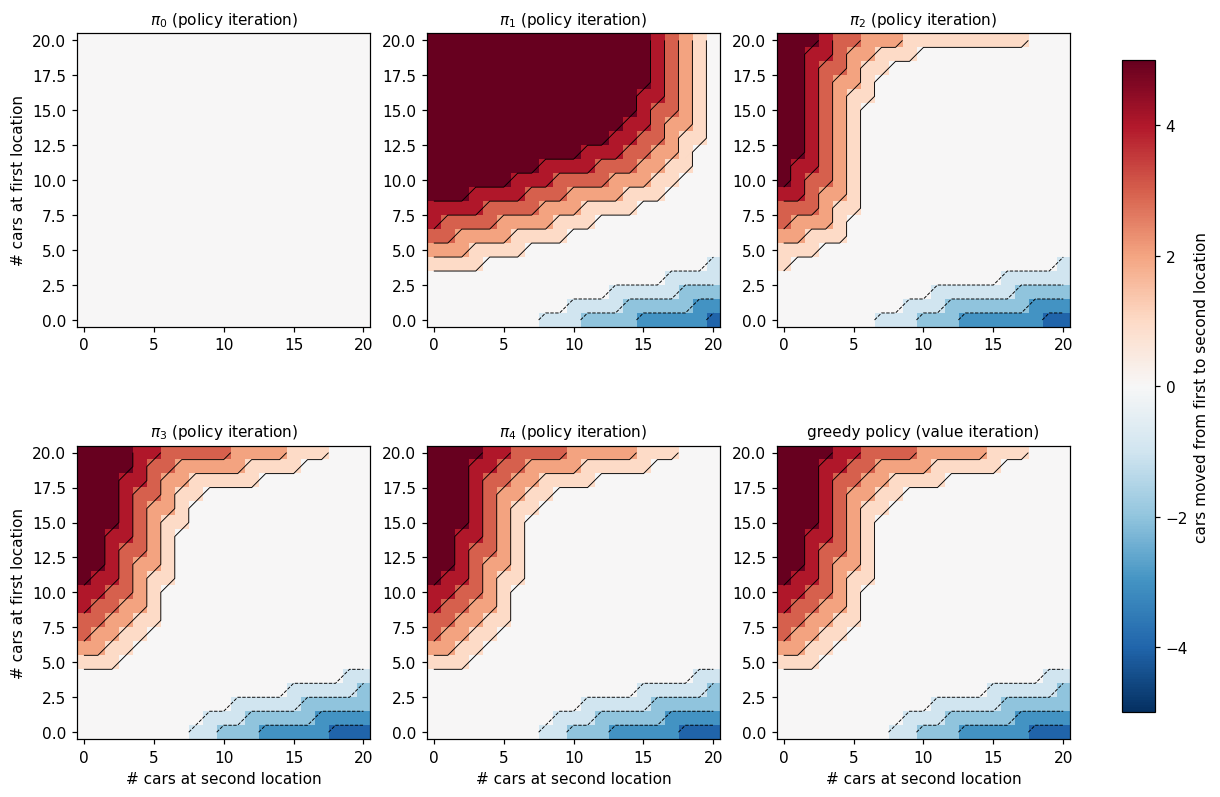

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(11, 7.5), layout="constrained")
panels = [(p, rf"$\pi_{k}$ (policy iteration)") for k, p in enumerate(policies)]
panels.append((pi_vi_jack, "greedy policy (value iteration)"))
for ax, (pi, title) in zip(axes.flat, panels):
    im = ax.imshow(pi, origin="lower", cmap="RdBu_r", vmin=-5, vmax=5)
    ax.contour(pi, levels=np.arange(-4.5, 5), colors="k", linewidths=0.6)
    ax.set_title(title, fontsize=10)
for ax in axes[1]:
    ax.set_xlabel("# cars at second location")
for ax in axes[:, 0]:
    ax.set_ylabel("# cars at first location")
fig.colorbar(im, ax=axes, shrink=0.8, label="cars moved from first to second location")
fig.savefig("figures/jack_policies.pdf", bbox_inches="tight")
plt.show()

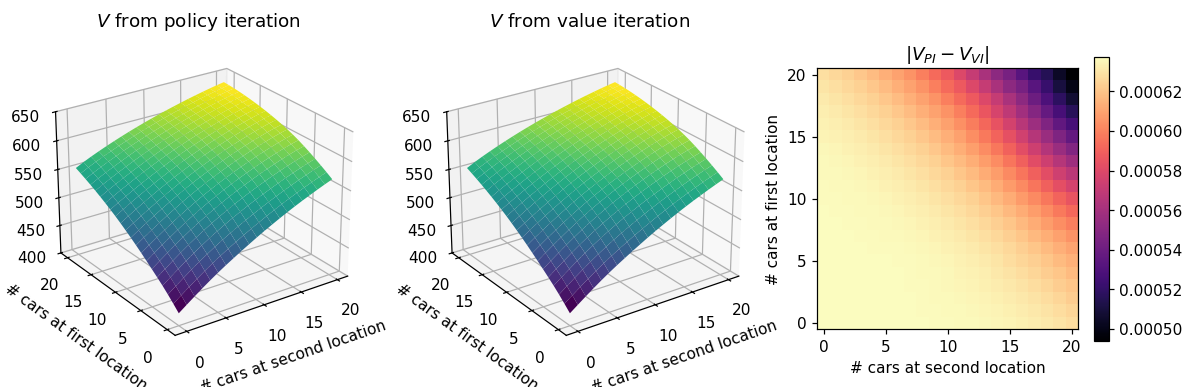

In [11]:
fig = plt.figure(figsize=(13, 4.2))
for k, (V, title) in enumerate([(V_pi_jack, "$V$ from policy iteration"),
                                (V_vi_jack, "$V$ from value iteration")]):
    ax = fig.add_subplot(1, 3, k + 1, projection="3d")
    ax.plot_surface(N2, N1, V, cmap="viridis")
    ax.set_xlabel("# cars at second location")
    ax.set_ylabel("# cars at first location")
    ax.set_zlim(400, 650)
    ax.set_title(title)
    ax.view_init(elev=25, azim=-125)
ax = fig.add_subplot(1, 3, 3)
im = ax.imshow(np.abs(V_pi_jack - V_vi_jack), origin="lower", cmap="magma")
ax.set_xlabel("# cars at second location")
ax.set_ylabel("# cars at first location")
ax.set_title(r"$|V_{PI} - V_{VI}|$")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.savefig("figures/jack_values.pdf", bbox_inches="tight")
plt.show()

The minimum of $V$ (about 421) matches Figure 4.2 of the book, but the maximum (about 637) is above the top label of the figure (612). The values depend on the Poisson tails. Many implementations ignore requests and returns of 11 or more, which loses some probability mass. With that truncation the values drop:

In [12]:
def truncated_location_model(lam_request, lam_return, n_max=11):
    P = np.zeros((MAX_CARS + 1, MAX_CARS + 1))
    R = np.zeros(MAX_CARS + 1)
    for m in range(MAX_CARS + 1):
        for req in range(n_max):
            rented = min(req, m)
            R[m] += poisson.pmf(req, lam_request) * RENT_INCOME * rented
            for ret in range(n_max):
                P[m, min(m - rented + ret, MAX_CARS)] += poisson.pmf(req, lam_request) * poisson.pmf(ret, lam_return)
    return P, R

def value_iteration_with(P1_, R1_, P2_, R2_, theta=1e-4):
    V = np.zeros((MAX_CARS + 1, MAX_CARS + 1))
    while True:
        W = P1_ @ V @ P2_.T
        V_new = np.max([np.where(feasible, -MOVE_COST * abs(a) + R1_[m1] + R2_[m2] + GAMMA * W[m1, m2], -np.inf)
                        for a, (m1, m2, feasible) in zip(ACTS, MORNING)], axis=0)
        if np.max(np.abs(V_new - V)) < theta:
            return V_new
        V = V_new

V_trunc = value_iteration_with(*truncated_location_model(3, 3), *truncated_location_model(4, 2))
print(f"exact model:     V from {V_vi_jack.min():.1f} to {V_vi_jack.max():.1f}")
print(f"truncated at 11: V from {V_trunc.min():.1f} to {V_trunc.max():.1f}")

exact model:     V from 421.4 to 637.0
truncated at 11: V from 406.1 to 617.9


## Exercise 3: a quick check of the $Q$-based algorithms

The pseudo-code is in the PDF. Here I run both $Q$-based algorithms on the gridworld of Exercise 1 and check that they recover $V^*$ and an optimal policy.

In [13]:
def q_policy_iteration(theta=1e-10):
    pi = np.full((17, 4), 0.25)                      # uniform initial policy
    Q = np.zeros((17, 4))
    n_iter = 0
    while True:
        # evaluation: Q(s,a) <- -1 + sum_a' pi(a'|s') Q(s',a'), with Q = 0 at terminal states
        while True:
            Q_new = np.zeros_like(Q)
            for s in NON_TERMINAL:
                s2 = NEXT[s]
                Q_new[s] = -1 + np.sum(pi[s2] * Q[s2], axis=1)
            delta = np.max(np.abs(Q_new - Q))
            Q = Q_new
            if delta < theta:
                break
        n_iter += 1
        # improvement: greedy w.r.t. Q, keeping the old action when it is still greedy
        new_pi = np.zeros_like(pi)
        for s in NON_TERMINAL:
            greedy = np.flatnonzero(Q[s] >= Q[s].max() - 1e-9)
            old = np.flatnonzero(pi[s] > 0)
            new_pi[s, old[0] if len(old) == 1 and old[0] in greedy else greedy[0]] = 1.0
        for s in TERMINAL:
            new_pi[s] = 0.25
        if np.array_equal(new_pi, pi):
            return Q, pi, n_iter
        pi = new_pi

def q_value_iteration(theta=1e-10):
    Q = np.zeros((17, 4))
    sweeps = 0
    while True:
        Q_new = np.zeros_like(Q)
        for s in NON_TERMINAL:
            Q_new[s] = -1 + Q[NEXT[s]].max(axis=1)
        sweeps += 1
        delta = np.max(np.abs(Q_new - Q))
        Q = Q_new
        if delta < theta:
            return Q, sweeps

Q_pi_it, pi_q, n_iter = q_policy_iteration()
Q_vi, sweeps = q_value_iteration()
print(f"Q-policy iteration: {n_iter} iterations, max |max_a Q - V*| = {np.max(np.abs(Q_pi_it.max(1) - V_star)):.1e}")
print(f"Q-value iteration:  {sweeps} sweeps,     max |max_a Q - V*| = {np.max(np.abs(Q_vi.max(1) - V_star)):.1e}")

Q-policy iteration: 2 iterations, max |max_a Q - V*| = 0.0e+00
Q-value iteration:  5 sweeps,     max |max_a Q - V*| = 0.0e+00


## Exercise 4: evaluating the uniform policy

### 4.1 Iterative policy evaluation

Initialization $V = 0$, synchronous sweeps with exact expected updates, stopping when $\max_s |V_{k+1}(s) - V_k(s)| < \theta$.

In [14]:
print(" theta    sweeps   max |V - V_exact|")
V_exact = np.array([float(V_unif_exact.get(s, 0)) for s in range(17)])
for theta in [1e-2, 1e-4, 1e-6, 1e-8, 1e-10]:
    V, sweeps = policy_evaluation(pi_uniform, theta=theta)
    print(f"{theta:6.0e} {sweeps:8d}   {np.max(np.abs(V - V_exact)):.2e}")

V_pi, pe_sweeps = policy_evaluation(pi_uniform, theta=1e-10)

# the error contracts like rho^k, where rho is the spectral radius of the
# transition matrix of the uniform policy restricted to non-terminal states
P_nt = np.zeros((14, 14))
for s in NON_TERMINAL:
    for s2 in NEXT[s]:
        if s2 not in TERMINAL:
            P_nt[idx[s], idx[s2]] += 0.25
rho = max(abs(np.linalg.eigvals(P_nt)))
print(f"\nspectral radius rho = {rho:.4f}; sweeps per factor 100 = {np.log(0.01) / np.log(rho):.1f}")

 theta    sweeps   max |V - V_exact|
 1e-02       76   1.44e-01
 1e-04      146   1.45e-03
 1e-06      216   1.45e-05
 1e-08      286   1.46e-07
 1e-10      356   1.46e-09

spectral radius rho = 0.9364; sweeps per factor 100 = 70.1


### 4.2 Monte Carlo prediction

All rewards are $-1$, so the return from time $t$ of an episode that ends at time $\tau$ is $G_t = -(\tau - t)$. $V^k$ is the running average of the returns collected in the first $k$ episodes, with $V^k(s) = 0$ for states that have not been visited yet.

In [15]:
def generate_episode(s, rng):
    # follow the uniform policy from s until a terminal state; returns visited states and actions
    states, actions = [], []
    while s not in TERMINAL:
        a = rng.integers(4)
        states.append(s)
        actions.append(a)
        s = NEXT[s, a]
    return np.array(states), np.array(actions)

def first_visit_mask(keys):
    _, first = np.unique(keys, return_index=True)
    mask = np.zeros(len(keys), dtype=bool)
    mask[first] = True
    return mask

def mc_prediction(K, first_visit, exploring_starts, rng, estimate_q=False):
    # returns the final estimate of V^pi and eps_k = ||V^pi - V^k||_inf for k = 0..K
    total = np.zeros((17, 4) if estimate_q else 17)
    count = np.zeros_like(total)
    est = np.zeros_like(total)
    to_v = (lambda Q: Q.mean(axis=1)) if estimate_q else (lambda V: V)
    errors = [np.max(np.abs(V_pi - to_v(est)))]
    for _ in range(K):
        s0 = rng.choice(NON_TERMINAL) if exploring_starts else 16
        states, actions = generate_episode(s0, rng)
        T = len(states)
        G = -(T - np.arange(T))
        key = (states, actions) if estimate_q else states
        if first_visit:
            keep = first_visit_mask(states * 4 + actions if estimate_q else states)
            key = (states[keep], actions[keep]) if estimate_q else states[keep]
            G = G[keep]
        np.add.at(total, key, G)
        np.add.at(count, key, 1)
        seen = count > 0
        est[seen] = total[seen] / count[seen]
        errors.append(np.max(np.abs(V_pi - to_v(est))))
    return to_v(est), np.array(errors)

VARIANTS = [("every-visit, $S_0 = 16$", False, False),
            ("every-visit, exploring starts", False, True),
            ("first-visit, $S_0 = 16$", True, False),
            ("first-visit, exploring starts", True, True)]

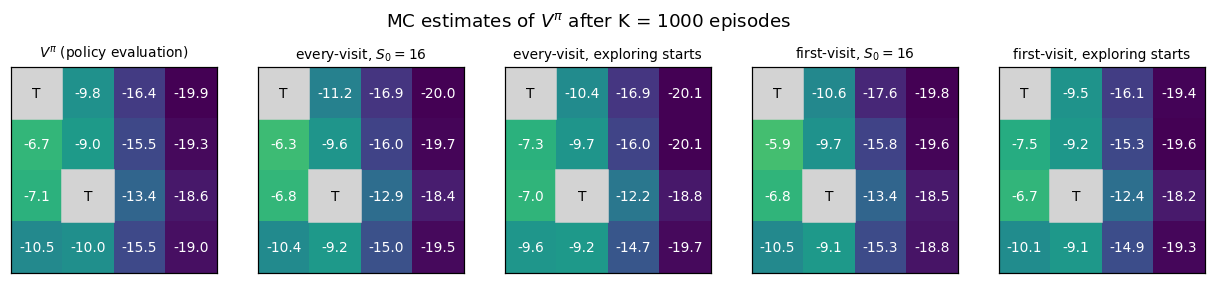

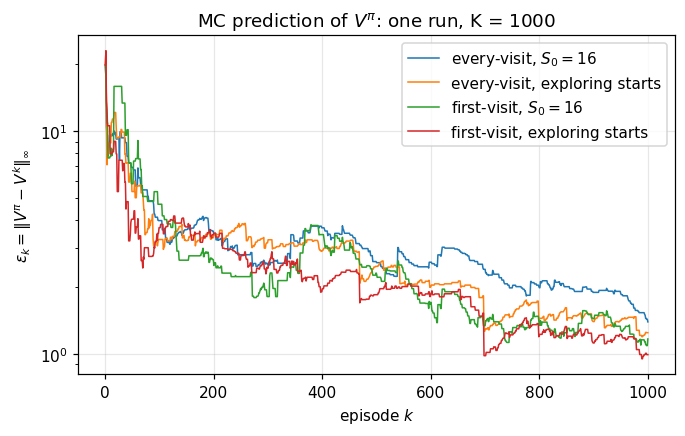

every-visit, $S_0 = 16$          eps_K = 1.40
every-visit, exploring starts    eps_K = 1.25
first-visit, $S_0 = 16$          eps_K = 1.17
first-visit, exploring starts    eps_K = 1.00


In [16]:
def run_variants(K, estimate_q, seed=0):
    results = {}
    for name, first, es in VARIANTS:
        rng = np.random.default_rng(seed)
        results[name] = mc_prediction(K, first, es, rng, estimate_q)
    return results

def plot_values(results, filename, suptitle):
    fig, axes = plt.subplots(1, 5, figsize=(14, 3))
    plot_grid_values(axes[0], V_pi, r"$V^\pi$ (policy evaluation)")
    for ax, (name, (V, _)) in zip(axes[1:], results.items()):
        plot_grid_values(ax, V, name)
    fig.suptitle(suptitle)
    fig.savefig(filename, bbox_inches="tight")
    plt.show()

def plot_errors(results, filename, title, logy=True):
    fig, ax = plt.subplots(figsize=(7, 4))
    for name, (_, err) in results.items():
        ax.plot(err, label=name, lw=1)
    ax.set_xlabel("episode $k$")
    ax.set_ylabel(r"$\epsilon_k = \|V^\pi - V^k\|_\infty$")
    if logy:
        ax.set_yscale("log")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    fig.savefig(filename, bbox_inches="tight")
    plt.show()

K = 1000
mc_v = run_variants(K, estimate_q=False)
plot_values(mc_v, "figures/mc_v_values.pdf", f"MC estimates of $V^\\pi$ after K = {K} episodes")
plot_errors(mc_v, "figures/mc_v_errors.pdf", f"MC prediction of $V^\\pi$: one run, K = {K}")
for name, (V, err) in mc_v.items():
    print(f"{name:32s} eps_K = {err[-1]:.2f}")

A single run is noisy, so I also average $\epsilon_k$ over 30 independent runs with $K = 5000$ episodes.

(16.7 s)


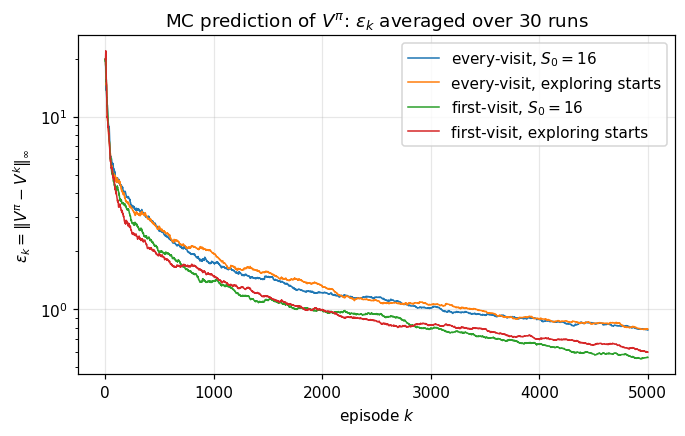

average eps_k at k =      100    1000    5000
every-visit, $S_0 = 16$            4.75    1.73    0.78
every-visit, exploring starts      4.61    1.93    0.79
first-visit, $S_0 = 16$            4.17    1.40    0.56
first-visit, exploring starts      4.05    1.48    0.60


In [17]:
def average_errors(K, estimate_q, n_runs=30):
    avg = {}
    for name, first, es in VARIANTS:
        errs = [mc_prediction(K, first, es, np.random.default_rng(1000 + i), estimate_q)[1]
                for i in range(n_runs)]
        avg[name] = (None, np.mean(errs, axis=0))
    return avg

t0 = time.perf_counter()
avg_v = average_errors(5000, estimate_q=False)
print(f"({time.perf_counter() - t0:.1f} s)")
plot_errors(avg_v, "figures/mc_v_errors_avg.pdf",
            r"MC prediction of $V^\pi$: $\epsilon_k$ averaged over 30 runs")
print("average eps_k at k =      100    1000    5000")
for name, (_, err) in avg_v.items():
    print(f"{name:32s} {err[100]:6.2f} {err[1000]:7.2f} {err[5000]:7.2f}")

**Why does first-visit converge faster?** For a state $s$, the first-visit estimate averages one return per episode that visits $s$, so after $k$ episodes its variance is about $\sigma^2_{\text{first}}(s)/k$ with $\sigma^2_{\text{first}}(s) = \mathbb{E}\big[(G_{\text{first}} - V^\pi(s))^2 \mathbb{1}_{\text{visit}}\big] / \mathbb{P}(\text{visit})^2$. The every-visit estimate is a ratio of sums over episodes, so its variance is about $\sigma^2_{\text{every}}(s)/k$ with $\sigma^2_{\text{every}}(s) = \mathbb{E}\big[(\sum_j (G_{t_j} - V^\pi(s)))^2\big] / \mathbb{E}[N_s]^2$, where $t_j$ are the visit times and $N_s$ the number of visits. I estimate both constants by simulation.

In [18]:
def asymptotic_variances(exploring_starts, n_episodes, rng):
    p_visit, n_visits = np.zeros(17), np.zeros(17)
    sq_first, sq_every = np.zeros(17), np.zeros(17)
    for _ in range(n_episodes):
        s0 = rng.choice(NON_TERMINAL) if exploring_starts else 16
        states, _ = generate_episode(s0, rng)
        T = len(states)
        dev = -(T - np.arange(T)) - V_pi[states]          # G_t - V(S_t)
        keep = first_visit_mask(states)
        np.add.at(p_visit, states[keep], 1)
        np.add.at(n_visits, states, 1)
        np.add.at(sq_first, states[keep], dev[keep] ** 2)
        per_state = np.zeros(17)
        np.add.at(per_state, states, dev)
        sq_every += per_state ** 2
    p_visit, n_visits = p_visit / n_episodes, n_visits / n_episodes
    return p_visit, n_visits, sq_first / n_episodes / p_visit ** 2, sq_every / n_episodes / n_visits ** 2

rng = np.random.default_rng(7)
with np.errstate(divide="ignore", invalid="ignore"):
    for es in [False, True]:
        p, n, var_first, var_every = asymptotic_variances(es, 50000, rng)
        print("exploring starts" if es else "S_0 = 16")
        print("  s   P(visit)  E[N_s]  sigma2_first  sigma2_every  ratio")
        for s in NON_TERMINAL:
            print(f"{s:3d} {p[s]:9.3f} {n[s]:7.2f} {var_first[s]:12.0f} {var_every[s]:13.0f} {var_every[s] / var_first[s]:6.2f}")
        print(f"max over states: first {np.nanmax(var_first[NON_TERMINAL]):.0f}, every {np.nanmax(var_every[NON_TERMINAL]):.0f}\n")

S_0 = 16
  s   P(visit)  E[N_s]  sigma2_first  sigma2_every  ratio
  2     0.239    0.49          723          1062   1.47
  3     0.314    1.00          727          1140   1.57
  4     0.290    1.34          808          1437   1.78
  5     0.145    0.26          685          1071   1.56
  6     0.302    0.48          515           892   1.73
  7     0.483    1.17          463           734   1.59
  8     0.469    1.67          499           790   1.58
  9     0.148    0.30          622           859   1.38
 11     0.732    1.49          304           427   1.41
 12     0.735    2.54          322           483   1.50
 13     0.192    0.64          662          1069   1.61
 14     0.442    0.97          358           586   1.64
 15     0.769    2.28          281           486   1.73
 16     1.000    4.41          232           372   1.61
max over states: first 808, every 1437

exploring starts
  s   P(visit)  E[N_s]  sigma2_first  sigma2_every  ratio
  2     0.341    0.69          534

## Exercise 5 (bonus): estimating $Q^\pi$ instead of $V^\pi$

Same four algorithms, but the returns are averaged per state-action pair. After each episode, $V^k(s) = \sum_a \pi(a|s) Q^k(s,a) = \frac14 \sum_a Q^k(s,a)$. Since $\pi$ is uniform, the first action of every episode is already random, so "exploring starts" only needs a random $S_0$.

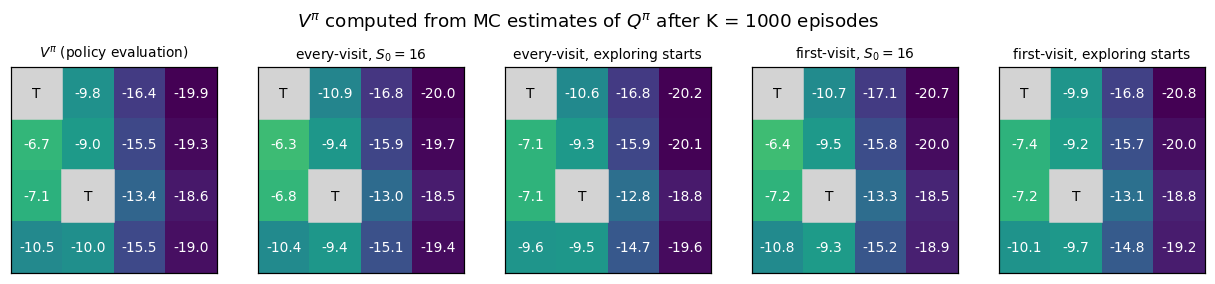

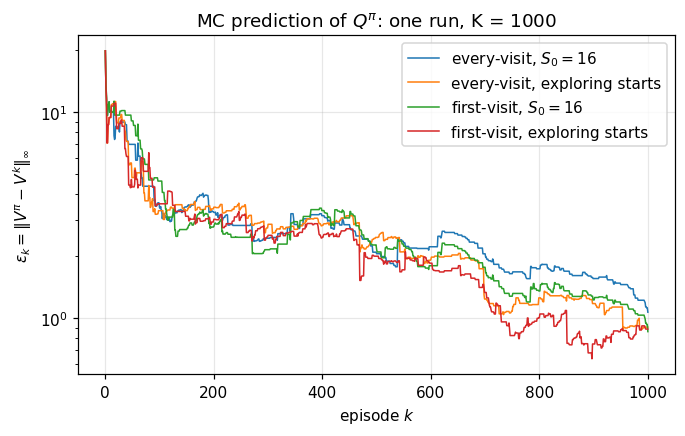

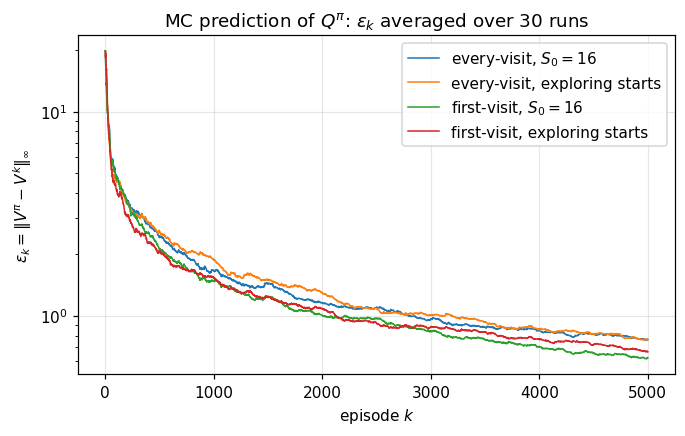

average eps_k at k =      100    1000    5000
every-visit, $S_0 = 16$            4.80    1.66    0.77
every-visit, exploring starts      4.60    1.87    0.76
first-visit, $S_0 = 16$            4.74    1.48    0.62
first-visit, exploring starts      4.18    1.53    0.67


In [19]:
mc_q = run_variants(K, estimate_q=True)
plot_values(mc_q, "figures/mc_q_values.pdf",
            f"$V^\\pi$ computed from MC estimates of $Q^\\pi$ after K = {K} episodes")
plot_errors(mc_q, "figures/mc_q_errors.pdf", f"MC prediction of $Q^\\pi$: one run, K = {K}")

avg_q = average_errors(5000, estimate_q=True)
plot_errors(avg_q, "figures/mc_q_errors_avg.pdf",
            r"MC prediction of $Q^\pi$: $\epsilon_k$ averaged over 30 runs")
print("average eps_k at k =      100    1000    5000")
for name, (_, err) in avg_q.items():
    print(f"{name:32s} {err[100]:6.2f} {err[1000]:7.2f} {err[5000]:7.2f}")

## Exercise 6 (bonus): Monte Carlo policy iteration

Policy evaluation uses first-visit MC estimation of $Q^\pi$ from Exercise 5. A greedy policy is deterministic, so to make sure every pair $(s, a)$ is tried I use exploring starts on both $S_0$ and $A_0$. The improvement step is the usual greedy step, keeping the old action when it is still greedy. A deterministic policy can loop forever, so episodes are cut after `horizon` steps. A looping action then gets a very negative return and is not chosen again.

In [20]:
def mc_q_evaluation(pi, n_episodes, rng, horizon=200):
    total = np.zeros((17, 4))
    count = np.zeros((17, 4))
    for _ in range(n_episodes):
        s, a = rng.choice(NON_TERMINAL), rng.integers(4)
        states, actions = [], []
        while s not in TERMINAL and len(states) < horizon:
            states.append(s)
            actions.append(a)
            s = NEXT[s, a]
            if s not in TERMINAL:
                # pi is either uniform or deterministic
                a = rng.integers(4) if pi[s].max() < 1 else int(np.argmax(pi[s]))
        states, actions = np.array(states), np.array(actions)
        T = len(states)
        G = -(T - np.arange(T))
        keep = first_visit_mask(states * 4 + actions)
        np.add.at(total, (states[keep], actions[keep]), G[keep])
        np.add.at(count, (states[keep], actions[keep]), 1)
    Q = np.where(count > 0, total / np.maximum(count, 1), -np.inf)
    Q[list(TERMINAL)] = 0
    return Q

def mc_policy_iteration(n_episodes=2000, max_iter=20, seed=0):
    rng = np.random.default_rng(seed)
    pi = np.full((17, 4), 0.25)
    for n_iter in range(1, max_iter + 1):
        Q = mc_q_evaluation(pi, n_episodes, rng)
        new_pi = np.full((17, 4), 0.25)
        for s in NON_TERMINAL:
            greedy = np.flatnonzero(Q[s] >= Q[s].max() - 1e-9)
            old = np.flatnonzero(pi[s] > 0)
            new_pi[s] = 0
            new_pi[s, old[0] if len(old) == 1 and old[0] in greedy else greedy[0]] = 1.0
        if np.array_equal(new_pi, pi):
            return pi, Q, n_iter
        pi = new_pi
    return pi, Q, max_iter

pi_mc, Q_mc, n_iter = mc_policy_iteration()
V_mc = Q_mc[np.arange(17), np.argmax(pi_mc, axis=1)]   # V(s) = Q(s, pi(s)) for a deterministic policy
print(f"MC policy iteration stopped after {n_iter} iterations")
print("V of the final policy (from the MC estimate of Q):")
show_grid(lambda s: f"{V_mc[s]:.0f}")
print("final policy:")
show_grid(lambda s: ARROWS[np.argmax(pi_mc[s])])
print("same values as V*:", np.allclose(V_mc[NON_TERMINAL], V_star[NON_TERMINAL]))

ok, iters = [], []
for seed in range(20):
    p, Q, n = mc_policy_iteration(seed=seed)
    ok.append(np.allclose(Q[NON_TERMINAL, np.argmax(p[NON_TERMINAL], axis=1)], V_star[NON_TERMINAL]))
    iters.append(n)
print(f"\n20 seeds: optimal policy found {sum(ok)}/20 times, iterations: {sorted(iters)}")

MC policy iteration stopped after 2 iterations
V of the final policy (from the MC estimate of Q):
        T        -1        -2        -3
       -1        -1        -2        -3
       -1         T        -1        -2
       -2        -1        -2        -3
final policy:
        T         ←         ←         ←
        ↑         ↓         ←         ←
        →         T         ←         ←
        ↑         ↑         ←         ←
same values as V*: True

20 seeds: optimal policy found 20/20 times, iterations: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
